# Maia Lite — Corpus v8 Quality Audit
**Google Colab | Independent, read-only audit | Version 1.0**

Audit the **existing** `acquisition_v8_5_001` corpus without running Hugging Face streaming or modifying committed chunks. The corpus remains **quarantined pending rights review**.

**Goals:** chunk integrity, record/schema consistency, exact and approximate duplicates, language plausibility, text quality, distribution, tokenization estimates, source provenance, and an explicit release gate.

**Important:** ~8.18 billion *proxy* tokens is not a count of Maia tokenizer tokens. A sampled audit does not establish full-corpus integrity or rights clearance.

Run cells in order. The default is a **stratified sample audit**; set `AUDIT_MODE = "full"` for an exhaustive scan (can take many hours). All generated outputs go to a new audit report directory, not the acquisition directory.

In [1]:
%pip -q install pandas matplotlib psutil transformers tokenizers

In [2]:
import os, json, gzip, re, hashlib, random, time, math, csv, unicodedata, statistics
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').is_dir():
        drive.mount('/content/drive', timeout_ms=300000)
    else:
        print('Google Drive already mounted.')
except ImportError:
    print('Not in Colab; set ROOT to the mounted corpus path.')

ROOT = Path('/content/drive/MyDrive/Colab_LLMs/Maia_Lite_0_3_0_Chat')
RUN_ID = 'acquisition_v8_5_001'
RUN_DIR = ROOT / 'corpus_v8' / 'runs' / RUN_ID
CANDIDATES = RUN_DIR / 'quarantine_pending_rights_review'
ACQ_REPORTS = RUN_DIR / 'reports'
AUDIT_DIR = RUN_DIR / 'quality_audit_v1'
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

# Default is safe and relatively fast; 'full' scans all committed gzip chunks.
AUDIT_MODE = 'sample'            # 'sample' or 'full'
SAMPLE_CHUNKS_PER_JOB = 32       # deterministic, spread across the file sequence
SEED = 20261024
MAX_EXAMPLES_PER_JOB = 600       # bounded reservoir for expensive NLP diagnostics
MAX_EXAMPLE_CHARS = 3000
TOKENIZER_PATH = ''              # optional local tokenizer directory (Drive or /content)
RUN_TOKENIZER_AUDIT = False      # explicitly opt in, never download unknown tokenizer
RUN_LANGUAGE_MODEL_CHECK = False # optional, requires extra library (see cell below)
assert AUDIT_MODE in ('sample', 'full')
assert CANDIDATES.is_dir(), f'Corpus directory not found: {CANDIDATES}'
print('Corpus:', CANDIDATES)
print('Reports:', AUDIT_DIR)
print('Audit mode:', AUDIT_MODE)
print('This notebook does not edit committed chunks or start acquisition.')

Mounted at /content/drive
Corpus: /content/drive/MyDrive/Colab_LLMs/Maia_Lite_0_3_0_Chat/corpus_v8/runs/acquisition_v8_5_001/quarantine_pending_rights_review
Reports: /content/drive/MyDrive/Colab_LLMs/Maia_Lite_0_3_0_Chat/corpus_v8/runs/acquisition_v8_5_001/quality_audit_v1
Audit mode: sample
This notebook does not edit committed chunks or start acquisition.


## 1. Inventory and expected acquisition totals

Use the latest acquisition manifest as **reference only**; the audit independently counts the selected chunks. The reference manifest may be stale. Chunk filenames must match the six known jobs.

In [3]:
JOBS = [
 ('fineweb2_pt','pt','web',2624000000),
 ('fineweb2_es','es','web',1640000000),
 ('fineweb_edu_en','en','web',2296000000),
 ('wikipedia_pt','pt','wikipedia',656000000),
 ('wikipedia_en','en','wikipedia',574000000),
 ('wikipedia_es','es','wikipedia',410000000)
]
JOB_MAP = {x[0]: dict(language=x[1],family=x[2],target=x[3]) for x in JOBS}
CHUNK_RE = re.compile(r'^(.+)_chunk_(\d+)\.jsonl\.gz$')
files_by_job = {}
for job_id in JOB_MAP:
    files_by_job[job_id] = sorted(CANDIDATES.glob(f'{job_id}_chunk_*.jsonl.gz'))
all_files = sorted(CANDIDATES.glob('*.jsonl.gz'))
unrecognized = [str(f) for f in all_files if not any(f.name.startswith(j+'_chunk_') for j in JOB_MAP)]
inventory = []
for jid, files in files_by_job.items():
    ids = [int(CHUNK_RE.match(f.name).group(2)) for f in files if CHUNK_RE.match(f.name)]
    inventory.append(dict(job_id=jid, language=JOB_MAP[jid]['language'], family=JOB_MAP[jid]['family'],
                          chunks=len(files), total_compressed_gb=round(sum(f.stat().st_size for f in files)/1e9,3),
                          duplicate_chunk_numbers=len(ids)-len(set(ids)),
                          target_proxy_tokens=JOB_MAP[jid]['target']))
inventory_df = pd.DataFrame(inventory)
display(inventory_df)
print('Total chunks:', sum(len(x) for x in files_by_job.values()))
print('Unrecognized gzip filenames:', len(unrecognized))
if unrecognized: print('Examples:', unrecognized[:5])
inventory_df.to_csv(AUDIT_DIR/'inventory.csv', index=False)

,job_id,language,family,chunks,total_compressed_gb,duplicate_chunk_numbers,target_proxy_tokens
0,fineweb2_pt,pt,web,7510,4.927,0,2624000000
1,fineweb2_es,es,web,4442,2.990,0,1640000000
2,fineweb_edu_en,en,web,4151,3.884,0,2296000000
3,wikipedia_pt,pt,wikipedia,1944,1.100,0,656000000
4,wikipedia_en,en,wikipedia,1662,0.976,0,574000000
5,wikipedia_es,es,wikipedia,1312,0.704,0,410000000


Total chunks: 21021
Unrecognized gzip filenames: 0


## 2. Select chunks reproducibly

The sampled mode selects files spread over the source's chunk-index range, including endpoints. **This is not a random sample of all documents** and must not be described as representative. Full mode is necessary to verify every gzip file.

In [4]:
def select_files(files, limit):
    if len(files) <= limit: return list(files)
    # Evenly spaced across the acquisition order; reproducible.
    indexes = sorted(set(round(i*(len(files)-1)/(limit-1)) for i in range(limit)))
    return [files[i] for i in indexes]

selected_by_job = {
    jid: (list(files) if AUDIT_MODE=='full' else select_files(files, max(2,SAMPLE_CHUNKS_PER_JOB)))
    for jid,files in files_by_job.items()
}
print('Selected chunks:', sum(map(len,selected_by_job.values())))
print('Mode:', AUDIT_MODE)

Selected chunks: 192
Mode: sample


## 3. Stream JSONL and verify record-level consistency

Read **one line at a time**. Verify gzip CRC (on complete read), UTF-8/JSON, schema, job ID, byte length, proxy-token estimator, and SHA-256 of normalized text. Invalid files are recorded without changing the originals.

Exact-duplicate detection uses a disk-backed SQLite database on the ephemeral Colab SSD to avoid retaining millions of hashes in RAM. The SQLite database is temporary and rebuilt each run. For sampled mode, duplicates are checked **only within the audited sample**.

In [5]:
import sqlite3
DB_PATH = Path('/content/maia_audit_hashes.sqlite3') if Path('/content').exists() else Path('/tmp/maia_audit_hashes.sqlite3')
if DB_PATH.exists(): DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute('PRAGMA journal_mode=OFF')
conn.execute('PRAGMA synchronous=OFF')
conn.execute('CREATE TABLE seen (digest TEXT PRIMARY KEY)')
conn.commit()

def normalize_text(text):
    return re.sub(r'\s+', ' ', text.casefold()).strip()
def proxy_tokens(text):
    return max(1,round(len(text)/4))
def char_script_ratios(text):
    letters = [c for c in text if c.isalpha()]
    if not letters: return 0.0
    latin = sum('LATIN' in unicodedata.name(c,'') for c in letters)
    return latin/len(letters)
def text_features(text):
    n=len(text)
    words=re.findall(r'\b\w+\b',text,flags=re.UNICODE)
    unique=len(set(w.casefold() for w in words))
    control=sum((ord(c)<32 and c not in '\n\r\t') for c in text)
    return dict(chars=n, words=len(words), unique_word_ratio=unique/max(1,len(words)),
                replacement_chars=text.count('\ufffd'), control_chars=control,
                latin_letter_ratio=char_script_ratios(text),
                whitespace_ratio=sum(c.isspace() for c in text)/max(1,n),
                digit_ratio=sum(c.isdigit() for c in text)/max(1,n))

rng=random.Random(SEED)
samples={jid:[] for jid in JOB_MAP}
sample_seen=Counter()
job_totals=defaultdict(Counter)
issues=Counter()
bad_files=[]
per_chunk=[]
started=time.time()
print('Beginning read-only audit...', flush=True)

for jid, file_list in selected_by_job.items():
    for index, path in enumerate(file_list,1):
        chunk_stats=Counter()
        chunk_errors=Counter()
        try:
            with gzip.open(path,'rt',encoding='utf-8') as fh:
                for lineno,line in enumerate(fh,1):
                    chunk_stats['lines']+=1
                    try:
                        row=json.loads(line)
                        if not isinstance(row,dict): raise ValueError('JSON record is not an object')
                        text=row.get('text')
                        if not isinstance(text,str): raise ValueError('missing or nonstring text')
                        digest=hashlib.sha256(normalize_text(text).encode('utf-8')).hexdigest()
                        if row.get('normalized_sha256')!=digest: chunk_errors['sha256_mismatch']+=1
                        if row.get('job_id')!=jid: chunk_errors['job_id_mismatch']+=1
                        if row.get('text_bytes')!=len(text.encode('utf-8')): chunk_errors['text_bytes_mismatch']+=1
                        if row.get('proxy_tokens')!=proxy_tokens(text): chunk_errors['proxy_tokens_mismatch']+=1
                        if row.get('rights_status')!='pending_review': chunk_errors['unexpected_rights_status']+=1
                        if row.get('eligible_for_training') is not False: chunk_errors['unexpected_eligibility']+=1
                        if row.get('expected_language')!=JOB_MAP[jid]['language']: chunk_errors['language_metadata_mismatch']+=1
                        if len(text)<250: chunk_errors['short_text_under_250_chars']+=1
                        if len(text)>100000: chunk_errors['long_text_over_100k_chars']+=1
                        try:
                            conn.execute('INSERT INTO seen(digest) VALUES (?)',(digest,))
                        except sqlite3.IntegrityError:
                            chunk_errors['exact_duplicate_in_audit_scope']+=1
                        chunk_stats['docs']+=1
                        chunk_stats['proxy_tokens']+=int(row.get('proxy_tokens') or 0)
                        chunk_stats['bytes']+=len(text.encode('utf-8'))
                        # Reservoir sampling per job: uniform over records visited in that job.
                        sample_seen[jid]+=1
                        candidate={'job_id':jid,'language':JOB_MAP[jid]['language'],
                                   'family':JOB_MAP[jid]['family'],
                                   'text':text[:MAX_EXAMPLE_CHARS],
                                   'original_chars':len(text),
                                   'source_url_present':bool(row.get('source_url')),
                                   'source_document_id_present':bool(row.get('source_document_id')),
                                   'dataset_revision_present':bool(row.get('dataset_revision'))}
                        reservoir=samples[jid]
                        if len(reservoir)<MAX_EXAMPLES_PER_JOB:
                            reservoir.append(candidate)
                        else:
                            pos=rng.randrange(sample_seen[jid])
                            if pos<MAX_EXAMPLES_PER_JOB: reservoir[pos]=candidate
                    except Exception as exc:
                        chunk_errors['invalid_record']+=1
                        if chunk_errors['invalid_record']<=2:
                            bad_files.append({'file':path.name,'line':lineno,'error':repr(exc)[:250]})
            chunk_stats['gzip_read_ok']=1
        except Exception as exc:
            chunk_errors['gzip_or_io_error']+=1
            bad_files.append({'file':path.name,'error':repr(exc)[:300]})
        conn.commit()
        job_totals[jid].update(chunk_stats)
        issues.update(chunk_errors)
        per_chunk.append(dict(job_id=jid,file=path.name,**dict(chunk_stats),
                              errors=sum(chunk_errors.values()),**dict(chunk_errors)))
        if index%25==0 or index==len(file_list):
            print(f'{jid}: {index}/{len(file_list)} chunks, '
                  f'{job_totals[jid]["docs"]:,} valid docs, '
                  f'{sum(issues.values()):,} issues',flush=True)

conn.close()
chunk_df=pd.DataFrame(per_chunk).fillna(0)
chunk_df.to_csv(AUDIT_DIR/'chunk_audit.csv',index=False)
(AUDIT_DIR/'errors.json').write_text(json.dumps(bad_files,indent=2,ensure_ascii=False),encoding='utf-8')
print('Duration (minutes):',round((time.time()-started)/60,1))
print('Errors:',dict(issues))
print('Files with recorded examples:',len(bad_files))
print('Exact duplicate scope:', 'entire corpus' if AUDIT_MODE=='full' else 'selected chunks only')

Beginning read-only audit...
fineweb2_pt: 25/32 chunks, 12,061 valid docs, 0 issues
fineweb2_pt: 32/32 chunks, 15,205 valid docs, 0 issues
fineweb2_es: 25/32 chunks, 11,733 valid docs, 0 issues
fineweb2_es: 32/32 chunks, 14,897 valid docs, 0 issues
fineweb_edu_en: 25/32 chunks, 11,598 valid docs, 0 issues
fineweb_edu_en: 32/32 chunks, 14,042 valid docs, 0 issues
wikipedia_pt: 25/32 chunks, 12,094 valid docs, 0 issues
wikipedia_pt: 32/32 chunks, 15,287 valid docs, 0 issues
wikipedia_en: 25/32 chunks, 11,723 valid docs, 0 issues
wikipedia_en: 32/32 chunks, 14,859 valid docs, 0 issues
wikipedia_es: 25/32 chunks, 11,231 valid docs, 0 issues
wikipedia_es: 32/32 chunks, 14,621 valid docs, 0 issues
Duration (minutes): 1.8
Errors: {}
Files with recorded examples: 0
Exact duplicate scope: selected chunks only


## 4. Aggregate and compare quotas

Only **full** mode can confirm the complete corpus totals. The sampled mode reports the totals of the files it actually read; it must not be compared as if it covered the entire acquisition.

In [6]:
summary=[]
for jid,meta in JOB_MAP.items():
    x=job_totals[jid]
    summary.append(dict(job_id=jid,language=meta['language'],family=meta['family'],
                        audited_chunks=len(selected_by_job[jid]),
                        total_chunks=len(files_by_job[jid]),
                        audited_docs=x['docs'],audited_proxy_tokens=x['proxy_tokens'],
                        target_proxy_tokens=meta['target'],
                        coverage_chunks_pct=round(100*len(selected_by_job[jid])/max(1,len(files_by_job[jid])),2)))
summary_df=pd.DataFrame(summary)
display(summary_df)
summary_df.to_csv(AUDIT_DIR/'source_summary.csv',index=False)
if AUDIT_MODE=='full':
    print('FULL SCAN: total audited proxy tokens:',int(summary_df.audited_proxy_tokens.sum()))
    print('Difference from 8.2B target:',8_200_000_000-int(summary_df.audited_proxy_tokens.sum()))
else:
    print('SAMPLE ONLY: audited proxy totals are NOT whole-corpus totals.')

,job_id,language,family,audited_chunks,total_chunks,audited_docs,audited_proxy_tokens,target_proxy_tokens,coverage_chunks_pct
0,fineweb2_pt,pt,web,32,7510,15205,10769665,2624000000,0.43
1,fineweb2_es,es,web,32,4442,14897,11613229,1640000000,0.72
2,fineweb_edu_en,en,web,32,4151,14042,16884927,2296000000,0.77
3,wikipedia_pt,pt,wikipedia,32,1944,15287,10008271,656000000,1.65
4,wikipedia_en,en,wikipedia,32,1662,14859,10368776,574000000,1.93
5,wikipedia_es,es,wikipedia,32,1312,14621,9251177,410000000,2.44


SAMPLE ONLY: audited proxy totals are NOT whole-corpus totals.


## 5. Text quality diagnostics

A bounded, deterministic reservoir from each source is used to examine text length, lexical diversity, Unicode replacement characters, control characters, script plausibility, whitespace, and digit density. These are **heuristics**, not definitive measures of linguistic or scientific quality.

,job_id,language,sampled_docs,median_chars,median_words_in_excerpt,median_unique_word_ratio,mean_latin_ratio,replacement_char_docs,control_char_docs,url_present_pct,revision_present_pct
0,fineweb2_es,es,600,1971.5,328.0,0.551049,0.999918,0,0,100.0,100.0
1,fineweb2_pt,pt,600,1656.5,276.5,0.594564,0.999837,0,0,100.0,100.0
2,fineweb_edu_en,en,600,2924.5,455.5,0.527623,0.999958,0,0,100.0,100.0
3,wikipedia_en,en,600,1508.5,248.0,0.548690,0.999021,0,0,100.0,100.0
4,wikipedia_es,es,600,1224.0,199.5,0.583253,0.998968,0,0,100.0,100.0
5,wikipedia_pt,pt,600,1041.0,166.0,0.622586,0.999470,0,0,100.0,100.0


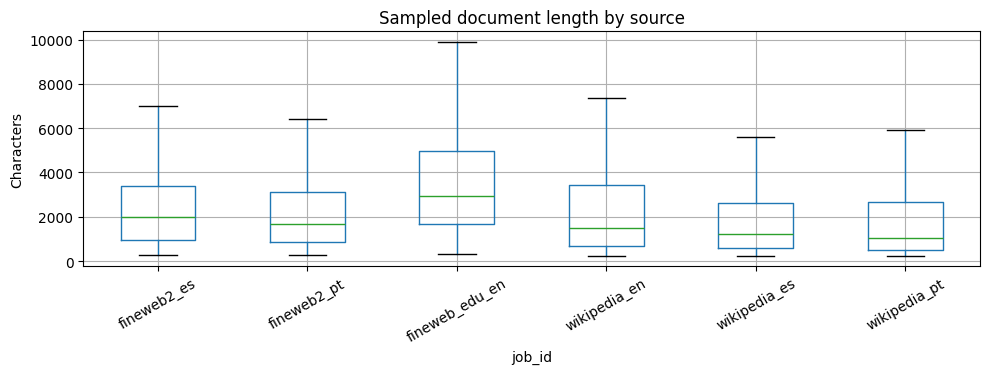

Sampled docs: 3600
No sampled document text is written to reports.


In [7]:
quality_rows=[]
for jid,records in samples.items():
    for r in records:
        f=text_features(r['text'])
        quality_rows.append({k:v for k,v in r.items() if k!='text'} | f)
quality_df=pd.DataFrame(quality_rows)
if len(quality_df):
    display(quality_df.groupby(['job_id','language']).agg(
        sampled_docs=('chars','size'),median_chars=('original_chars','median'),
        median_words_in_excerpt=('words','median'),
        median_unique_word_ratio=('unique_word_ratio','median'),
        mean_latin_ratio=('latin_letter_ratio','mean'),
        replacement_char_docs=('replacement_chars',lambda s:int((s>0).sum())),
        control_char_docs=('control_chars',lambda s:int((s>0).sum())),
        url_present_pct=('source_url_present',lambda s:round(100*s.mean(),1)),
        revision_present_pct=('dataset_revision_present',lambda s:round(100*s.mean(),1))
    ).reset_index())
    fig,ax=plt.subplots(figsize=(10,4))
    quality_df.boxplot(column='original_chars',by='job_id',ax=ax,rot=30,showfliers=False)
    ax.set_title('Sampled document length by source');ax.set_ylabel('Characters')
    plt.suptitle('');plt.tight_layout()
    fig.savefig(AUDIT_DIR/'sample_document_lengths.png',dpi=140)
    plt.show()
quality_df.to_csv(AUDIT_DIR/'quality_sample.csv',index=False)
print('Sampled docs:',len(quality_df))
print('No sampled document text is written to reports.')

## 6. Optional language identification

The metadata's expected language is not a measured language. Install `langid` and set `RUN_LANGUAGE_MODEL_CHECK=True` in configuration to estimate language on sampled excerpts. Language ID is fallible for code, quotations, multilingual pages and short text.

In [8]:
language_df=pd.DataFrame()
if RUN_LANGUAGE_MODEL_CHECK:
    %pip -q install langid
    import langid
    lang_rows=[]
    for jid,records in samples.items():
        for r in records:
            predicted,score=langid.classify(r['text'][:2000])
            lang_rows.append(dict(job_id=jid,expected=r['language'],predicted=predicted,
                                  matches_expected=(predicted==r['language']),score=score))
    language_df=pd.DataFrame(lang_rows)
    display(language_df.groupby('job_id').agg(
        sampled=('matches_expected','size'),
        predicted_match_pct=('matches_expected',lambda x:round(100*x.mean(),1))).reset_index())
    language_df.to_csv(AUDIT_DIR/'language_sample.csv',index=False)
else:
    print('Language ID not run. Set RUN_LANGUAGE_MODEL_CHECK=True and rerun this cell.')

Language ID not run. Set RUN_LANGUAGE_MODEL_CHECK=True and rerun this cell.


## 7. Optional Maia tokenizer calibration

For the *actual* Maia tokenizer, set `TOKENIZER_PATH` to its local directory (containing the tokenizer files) and enable `RUN_TOKENIZER_AUDIT`. We intentionally do not silently download or substitute GPT-2/Qwen tokenizers.

**Caution:** The stored reservoir keeps only the first `MAX_EXAMPLE_CHARS` characters of each document. This calibrates a sample of excerpts, **not full-document tokenizer totals**. Ratios may vary with document length, markup, language and source.

In [9]:
tokenizer_df=pd.DataFrame()
if RUN_TOKENIZER_AUDIT:
    assert TOKENIZER_PATH and Path(TOKENIZER_PATH).exists(), 'Provide an existing tokenizer directory.'
    from transformers import AutoTokenizer
    tokenizer=AutoTokenizer.from_pretrained(TOKENIZER_PATH,local_files_only=True,
                                             trust_remote_code=False,use_fast=True)
    rows=[]
    for jid,records in samples.items():
        for r in records:
            excerpt=r['text']
            if not excerpt: continue
            actual=len(tokenizer.encode(excerpt,add_special_tokens=False))
            rows.append(dict(job_id=jid,language=r['language'],family=r['family'],
                             excerpt_chars=len(excerpt),proxy_tokens=proxy_tokens(excerpt),
                             actual_tokens=actual,actual_over_proxy=actual/proxy_tokens(excerpt)))
    tokenizer_df=pd.DataFrame(rows)
    if len(tokenizer_df):
        display(tokenizer_df.groupby(['job_id','language']).agg(
            samples=('actual_tokens','size'),
            median_actual_over_proxy=('actual_over_proxy','median'),
            mean_actual_over_proxy=('actual_over_proxy','mean')).reset_index())
        tokenizer_df.to_csv(AUDIT_DIR/'tokenizer_calibration_sample.csv',index=False)
else:
    print('Actual tokenizer calibration NOT RUN; no claims about real token totals.')

Actual tokenizer calibration NOT RUN; no claims about real token totals.


## 8. Near-duplicate and benchmark contamination review

Normalized SHA-256 catches only **exact** duplicates. It does not detect paraphrases, boilerplate, translated copies or near-duplicates. The following **sample-only** character-shingle comparison is a quick signal; it is not an exhaustive near-duplicate audit. Benchmark contamination is not measured because no frozen benchmark was supplied.

In [10]:
# Cheap bounded heuristic: compare short normalized excerpts via 5-word shingles.
def shingles(text, n=5):
    words=re.findall(r'\w+',normalize_text(text[:1500]))
    return set(zip(*(words[i:] for i in range(n)))) if len(words)>=n else set()
rng_pairs=random.Random(SEED+1)
sample_pool=[r for recs in samples.values() for r in recs]
pair_results=[]
if len(sample_pool)>1:
    for _ in range(min(3000,len(sample_pool)*3)):
        a,b=rng_pairs.sample(sample_pool,2)
        A,B=shingles(a['text']),shingles(b['text'])
        score=len(A&B)/len(A|B) if A and B else 0
        if score>=0.70:
            pair_results.append(dict(job_a=a['job_id'],job_b=b['job_id'],
                                     jaccard_5gram=round(score,4)))
print('High-similarity pairs in random sample:',len(pair_results))
pd.DataFrame(pair_results,columns=['job_a','job_b','jaccard_5gram']).to_csv(
    AUDIT_DIR/'near_duplicate_sample_pairs.csv',index=False)
print('This does not estimate full-corpus near-duplicate prevalence.')
print('Benchmark contamination: NOT ASSESSED (no benchmark supplied).')

High-similarity pairs in random sample: 0
This does not estimate full-corpus near-duplicate prevalence.
Benchmark contamination: NOT ASSESSED (no benchmark supplied).


## 9. Rights, provenance, and release gate

Acquisition metadata (`rights_status='pending_review'`, `eligible_for_training=False`) is a **quarantine label**, not legal permission. Dataset-level terms, underlying source rights, redistribution, commercial use and provenance require independent review. The audit never automatically approves training.

Use `source_metadata.json` if present, but treat it as supporting metadata rather than proof of rights. Record decisions in a **separate human-reviewed document**.

In [11]:
source_metadata_path=ACQ_REPORTS/'source_metadata.json'
if source_metadata_path.exists():
    source_metadata=json.loads(source_metadata_path.read_text(encoding='utf-8'))
    print('Source metadata available:',list(source_metadata)[:10])
else:
    source_metadata={}
    print('Source metadata missing; provenance review blocked.')
rights_rows=[]
for jid,meta in JOB_MAP.items():
    rights_rows.append(dict(job_id=jid,language=meta['language'],family=meta['family'],
                            human_license_review='PENDING',
                            document_level_rights_review='PENDING',
                            redistribution_review='PENDING',
                            training_eligibility='NOT APPROVED'))
rights_df=pd.DataFrame(rights_rows)
display(rights_df)
rights_df.to_csv(AUDIT_DIR/'rights_review_template.csv',index=False)
print('Do not change these statuses automatically based on dataset metadata.')

Source metadata available: ['HuggingFaceFW/fineweb-2', 'HuggingFaceFW/fineweb-edu', 'wikimedia/wikipedia']


,job_id,language,family,human_license_review,document_level_rights_review,redistribution_review,training_eligibility
0,fineweb2_pt,pt,web,PENDING,PENDING,PENDING,NOT APPROVED
1,fineweb2_es,es,web,PENDING,PENDING,PENDING,NOT APPROVED
2,fineweb_edu_en,en,web,PENDING,PENDING,PENDING,NOT APPROVED
3,wikipedia_pt,pt,wikipedia,PENDING,PENDING,PENDING,NOT APPROVED
4,wikipedia_en,en,wikipedia,PENDING,PENDING,PENDING,NOT APPROVED
5,wikipedia_es,es,wikipedia,PENDING,PENDING,PENDING,NOT APPROVED


Do not change these statuses automatically based on dataset metadata.


## 10. Audit report and explicit blockers

The output is a **candidate corpus audit**, not a training authorization. The report distinguishes completed tests, sample-limited tests and unperformed tests. Source data remains untouched.

In [12]:
def now_utc(): return datetime.now(timezone.utc).isoformat()
total_errors=sum(issues.values())
report={
 'audit_version':'1.0','generated_utc':now_utc(),'run_id':RUN_ID,
 'mode':AUDIT_MODE,'selected_chunks':sum(map(len,selected_by_job.values())),
 'inventory_chunks':sum(map(len,files_by_job.values())),
 'audited_valid_docs':int(summary_df.audited_docs.sum()),
 'audited_proxy_tokens':int(summary_df.audited_proxy_tokens.sum()),
 'whole_corpus_totals_verified':AUDIT_MODE=='full' and total_errors==0 and not unrecognized,
 'issue_counts':dict(issues),'unrecognized_files':unrecognized,
 'source_summary':summary_df.to_dict(orient='records'),
 'sampling':'deterministic evenly spaced chunks; bounded reservoir per source',
 'exact_dedup_scope':'all audited records only',
 'near_duplicate_scope':'random sampled excerpt pairs only',
 'tokenizer_calibration_run':bool(RUN_TOKENIZER_AUDIT and len(tokenizer_df)),
 'language_id_run':bool(RUN_LANGUAGE_MODEL_CHECK and len(language_df)),
 'rights_status':'PENDING_HUMAN_REVIEW',
 'benchmark_contamination':'NOT_ASSESSED',
 'production_ready':False,
 'blockers':[
  'Human source/document rights and license review incomplete',
  'Training eligibility not approved; quarantine labels must be respected',
  'Benchmark contamination not audited',
  'No comprehensive near-duplicate audit',
  'No complete real-token count with frozen Maia tokenizer',
  'Scientific/linguistic quality requires manual inspection and acceptance criteria',
  'Wikipedia PT below original per-source quota'
 ]+(['Full-corpus integrity not verified: sample mode'] if AUDIT_MODE!='full' else [])
   +(['One or more record/chunk integrity issues detected'] if total_errors or unrecognized else []),
 'outputs':['inventory.csv','chunk_audit.csv','source_summary.csv','errors.json',
            'quality_sample.csv','sample_document_lengths.png','rights_review_template.csv']
}
out=AUDIT_DIR/'quality_audit_report.json'
out.write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
print('Report:',out)
print('Mode:',AUDIT_MODE)
print('Integrity issues:',total_errors)
print('Full corpus verified:',report['whole_corpus_totals_verified'])
print('Training approved:',report['production_ready'])
print('Important: audit results do not alter acquisition chunks or rights status.')

Report: /content/drive/MyDrive/Colab_LLMs/Maia_Lite_0_3_0_Chat/corpus_v8/runs/acquisition_v8_5_001/quality_audit_v1/quality_audit_report.json
Mode: sample
Integrity issues: 0
Full corpus verified: False
Training approved: False
Important: audit results do not alter acquisition chunks or rights status.
